In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
HBAR = 1.054571817e-34   
G_NEWTON = 6.67430e-11

  s =  0.1: entangled for about  51.6% of the plotted time window
  s =  1.5: entangled for about  78.5% of the plotted time window
  s =    5: entangled for about  68.7% of the plotted time window
  s =    7: entangled for about  68.7% of the plotted time window
  s =   10: entangled for about  69.0% of the plotted time window


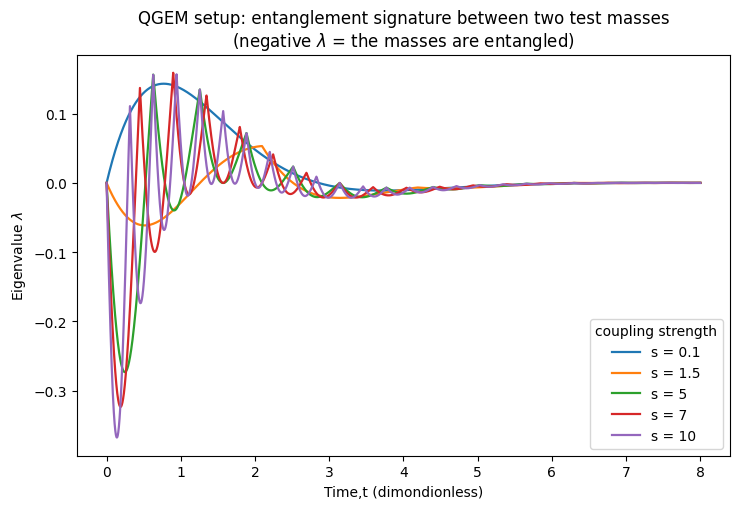

In [8]:
# QGEM (QuantumGravity via Entanglement of Masses)
def qgem_eigenvalue(t,s):
    return 0.5* np.exp(-t)* (np.sin(t)- np.abs(np.sin(s*t)))

def simulate_qgem():
    t = np.linspace(0,8,6000)
    s_values=[0.1,1.5,5,7,10]

    plt.figure(figsize=(7.5, 5.2))
    for s in s_values:
        lam = qgem_eigenvalue(t, s)
        plt.plot(t, lam, label=f"s = {s}", linewidth=1.6)
    plt.xlabel("Time,t (dimondionless)")
    plt.ylabel(r"Eigenvalue $\lambda$")
    plt.title("QGEM setup: entanglement signature between two test masses\n"
               r"(negative $\lambda$ = the masses are entangled)")
    plt.legend(title="coupling strength")
    plt.tight_layout()

    for s in s_values:
        lam = qgem_eigenvalue(t, s)
        entangled_fraction = np.mean(lam < 0)
        print(f"  s = {s:>4}: entangled for about "
              f"{entangled_fraction*100:5.1f}% of the plotted time window")
        
simulate_qgem()


=== 2. Entanglement entropy vs gravitational phase ===
  With m=1e-14 kg, l=200 um: entropy first peaks near t = 9.925 s


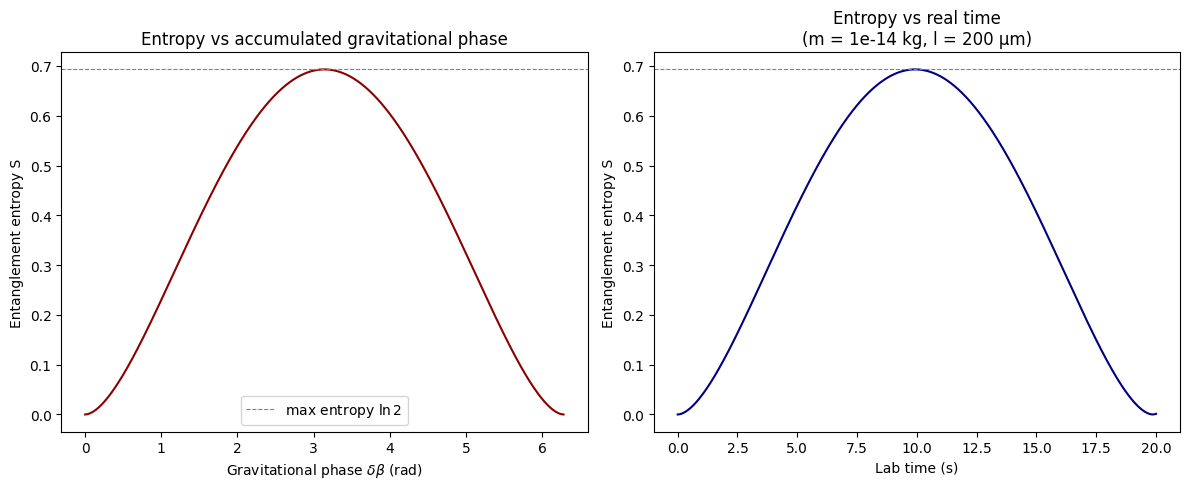

In [11]:
# enatanglement entropy and gravitational phase
def entanglement_entropy(delta_beta):
    root = np.sqrt(np.clip((1+np.cos(delta_beta))/ 2,0,1))
    rho_plus = 0.5*(1+root)
    rho_minus = 0.5*(1-root)
    eps = 1e-15
    s = -rho_plus* np.log(rho_plus + eps) - rho_minus * np.log(rho_minus + eps)
    return s

def simulate_entanglement_entropy():
    delta_beta = np.linspace(0,2*np.pi,2000)
    S = entanglement_entropy(delta_beta)

    
    m = 1e-14        # (a mesoscopic test mass, as proposed in the paper)
    l = 200e-6       # (initial separation between the two masses)
    t_lab = np.linspace(0, 20, 2000)  # seconds
    delta_beta_t = G_NEWTON * m**2 * t_lab / (l * HBAR)
    S_t = entanglement_entropy(delta_beta_t)
 
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
    axes[0].plot(delta_beta, S, color="darkred")
    axes[0].axhline(np.log(2), color="gray", linestyle="--", linewidth=0.8,
                     label=r"max entropy $\ln 2$")
    axes[0].set_xlabel(r"Gravitational phase $\delta\beta$ (rad)")
    axes[0].set_ylabel("Entanglement entropy S")
    axes[0].set_title("Entropy vs accumulated gravitational phase")
    axes[0].legend()
 
    axes[1].plot(t_lab, S_t, color="navy")
    axes[1].axhline(np.log(2), color="gray", linestyle="--", linewidth=0.8)
    axes[1].set_xlabel("Lab time (s)")
    axes[1].set_ylabel("Entanglement entropy S")
    axes[1].set_title(f"Entropy vs real time\n(m = {m:.0e} kg, l = {l*1e6:.0f} µm)")
 
    plt.tight_layout()
   
 
    t_to_max = t_lab[np.argmax(S_t)]
    print("\n=== 2. Entanglement entropy vs gravitational phase ===")
    print(f"  With m={m:.0e} kg, l={l*1e6:.0f} um: entropy first peaks near "
          f"t = {t_to_max:.3f} s")

simulate_entanglement_entropy()

In [16]:
# simple SG interferrometer
def sg_splitting(t, F0, m , tau):
    t= np.array(t, dtype = float)
    dp = np.where(t <= tau,F0*t, F0*tau)
    dz = np.where(
    t<=tau,
    (F0/m)*t**2 /2,
    (F0/m) *(t*tau-tau**2/2),
    )
    return dz, dp




=== 3. Simple Stern-Gerlach interference signal ===
  Wave-packet width delta_z = 1.00 um, momentum uncertainty delta_p = 5.27e-29 kg m/s
  Visibility drops to 50% at F0 ~ 1.23e-24 N


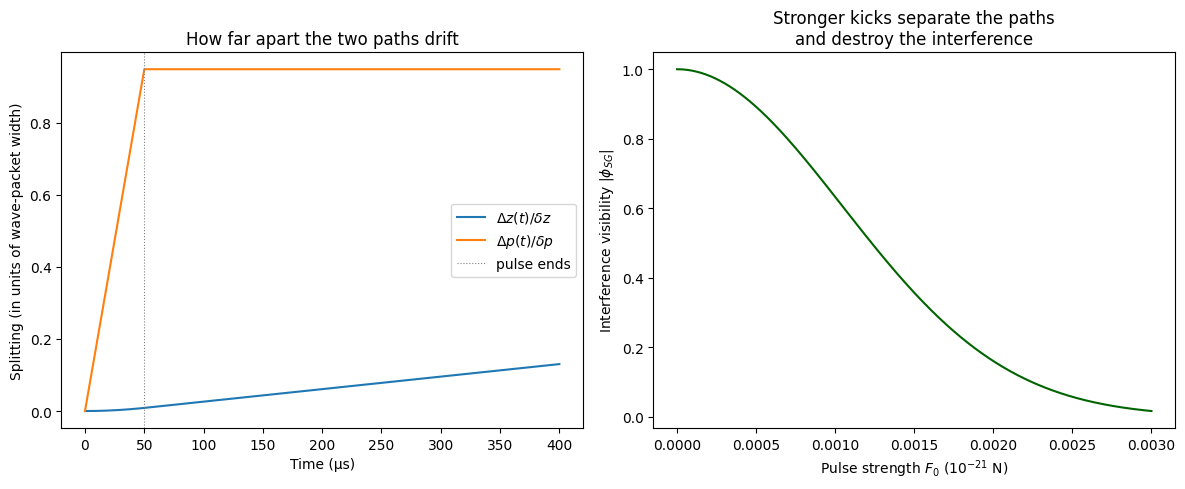

In [17]:
def sg_interference_signal(dz, dp, delta_z, delta_p):
    return np.exp(-0.5 * ((dz / delta_z) ** 2 + (dp / delta_p) ** 2))
 
 
def simulate_sg_interference():
    m = 1.44e-25       # kg  
    delta_z = 1e-6      # m    
    delta_p = HBAR / (2 * delta_z)  
    tau_pulse = 50e-6   # s    (50 microsecond)
 
    t = np.linspace(0, 400e-6, 3000)  
 
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
    #  splitting Delta_z, Delta_p vs time, for one pulse strength
    F0 = 1e-24   # N, a representative force (scaled so delta_p ~ order 1 by pulse end)
    dz, dp = sg_splitting(t, F0, m, tau_pulse)
    ax = axes[0]
    ax.plot(t * 1e6, dz / delta_z, label=r"$\Delta z(t)/\delta z$")
    ax.plot(t * 1e6, dp / delta_p, label=r"$\Delta p(t)/\delta p$")
    ax.axvline(tau_pulse * 1e6, color="gray", linestyle=":", linewidth=0.8,
               label="pulse ends")
    ax.set_xlabel("Time (µs)")
    ax.set_ylabel("Splitting (in units of wave-packet width)")
    ax.set_title("How far apart the two paths drift")
    ax.legend()
 
    #  interference signal strength vs pulse strength (F0)
    F0_values = np.linspace(0, 3e-24, 400)
    phi_at_end = []
    t_end = t[-1]
    for F0v in F0_values:
        dz_end, dp_end = sg_splitting(np.array([t_end]), F0v, m, tau_pulse)
        phi = sg_interference_signal(dz_end, dp_end, delta_z, delta_p)
        phi_at_end.append(phi[0])
    ax = axes[1]
    ax.plot(F0_values * 1e21, phi_at_end, color="darkgreen")
    ax.set_xlabel(r"Pulse strength $F_0$ ($10^{-21}$ N)")
    ax.set_ylabel(r"Interference visibility $|\phi_{SG}|$")
    ax.set_title("Stronger kicks separate the paths\nand destroy the interference")
 
    plt.tight_layout()
 
    print("\n=== 3. Simple Stern-Gerlach interference signal ===")
    print(f"  Wave-packet width delta_z = {delta_z*1e6:.2f} um, "
          f"momentum uncertainty delta_p = {delta_p:.2e} kg m/s")
    half_idx = np.argmin(np.abs(np.array(phi_at_end) - 0.5))
    print(f"  Visibility drops to 50% at F0 ~ {F0_values[half_idx]:.2e} N")

simulate_sg_interference()

In [18]:
def bec_scaling_factor(t, omega):
    return np.sqrt(1 + (omega * t) ** 2)

In [19]:
def bec_scaled_splitting(t, F0, m, tau_pulse, omega):
    dz, dp = sg_splitting(t, F0, m, tau_pulse)
    gamma = bec_scaling_factor(t, omega)
    # d(gamma)/dt = omega^2 * t / gamma
    dgamma_dt = (omega**2 * t) / gamma
    dz_tilde = dz * gamma
    dp_tilde = gamma * dp - m * dgamma_dt * dz
    return dz_tilde, dp_tilde

In [20]:
def simulate_bec_interference():
    m = 1.44e-25
    delta_z = 1e-6
    delta_p = HBAR / (2 * delta_z)
    tau_pulse = 50e-6
    F0 = 2e-25  
 
    t = np.linspace(1e-9, 500e-6, 3000)  
    
    omega_values = [0, 2 * np.pi * 500, 2 * np.pi * 2000, 2 * np.pi * 5000]
    labels = ["no trap (omega=0)", "500 Hz trap", "2 kHz trap", "5 kHz trap"]


=== 4. BEC interference signal ===
  no trap (omega=0): visibility stays above 50% for the whole window
       500 Hz trap: visibility stays above 50% for the whole window
        2 kHz trap: visibility stays above 50% for the whole window
        5 kHz trap: visibility stays above 50% for the whole window


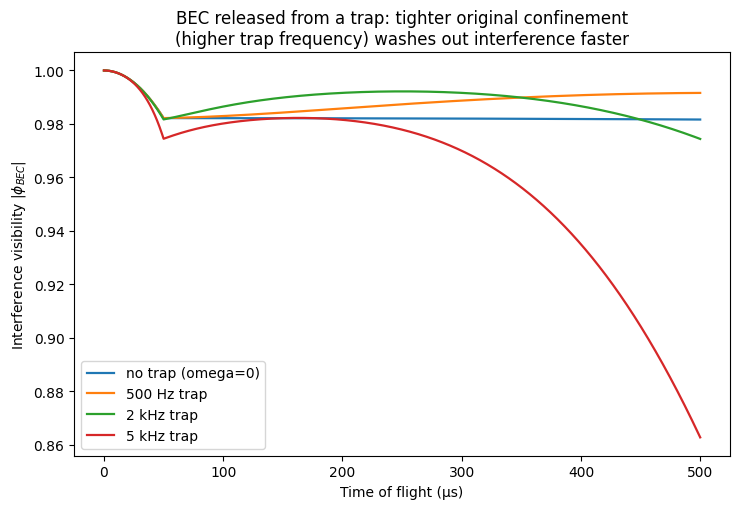

In [23]:
def bec_scaling_factor(t, omega):
    return np.sqrt(1 + (omega * t) ** 2)
 
 
def bec_scaled_splitting(t, F0, m, tau_pulse, omega):
    dz, dp = sg_splitting(t, F0, m, tau_pulse)
    gamma = bec_scaling_factor(t, omega)
    # d(gamma)/dt = omega^2 * t / gamma
    dgamma_dt = (omega**2 * t) / gamma
    dz_tilde = dz * gamma
    dp_tilde = gamma * dp - m * dgamma_dt * dz
    return dz_tilde, dp_tilde
 
 
def simulate_bec_interference():
    m = 1.44e-25
    delta_z = 1e-6
    delta_p = HBAR / (2 * delta_z)
    tau_pulse = 50e-6
    F0 = 2e-25   
 
    t = np.linspace(1e-9, 500e-6, 3000)  )
 
    omega_values = [0, 2 * np.pi * 500, 2 * np.pi * 2000, 2 * np.pi * 5000]
    labels = ["no trap (omega=0)", "500 Hz trap", "2 kHz trap", "5 kHz trap"]
 
    plt.figure(figsize=(7.5, 5.2))
    for omega, lab in zip(omega_values, labels):
        dz_t, dp_t = bec_scaled_splitting(t, F0, m, tau_pulse, omega)
        phi = sg_interference_signal(dz_t, dp_t, delta_z, delta_p)
        plt.plot(t * 1e6, phi, label=lab, linewidth=1.6)
 
    plt.xlabel("Time of flight (µs)")
    plt.ylabel(r"Interference visibility $|\phi_{BEC}|$")
    plt.title("BEC released from a trap: tighter original confinement\n"
               "(higher trap frequency) washes out interference faster")
    plt.legend()
    plt.tight_layout()

 
    print("\n=== 4. BEC interference signal ===")
    for omega, lab in zip(omega_values, labels):
        dz_t, dp_t = bec_scaled_splitting(t, F0, m, tau_pulse, omega)
        phi = sg_interference_signal(dz_t, dp_t, delta_z, delta_p)
        below_half = t[phi < 0.5]
        if len(below_half):
            print(f"  {lab:>16}: visibility falls below 50% at "
                  f"t = {below_half[0]*1e6:.1f} us")
        else:
            print(f"  {lab:>16}: visibility stays above 50% for the whole window")

simulate_bec_interference()